# Part I: First-principles experiments

Input shape: (4, 4, 3) (height, width, RGB channels)
Target: [0.25, 0.75] (one value per output neuron)


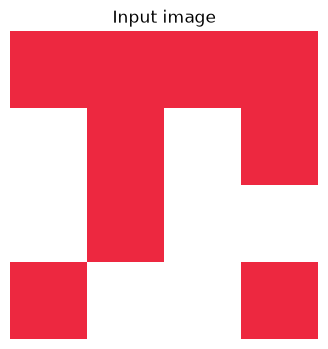

In [ ]:
import matplotlib.pyplot as plt
import torch

from data import get_logo_as_rgb_image_tensor
from first_principles_models import LinearModel, LinearSigmoidModel

RED, GREEN, BLUE = 0, 1, 2
CHANNEL_NAMES = {RED: "Red", GREEN: "Green", BLUE: "Blue"}

image = get_logo_as_rgb_image_tensor()
target = torch.tensor([0.25, 0.75], dtype=torch.float32)

print(f"Input shape: {tuple(image.shape)} (height, width, RGB channels)")
print(f"Target: {target.tolist()} (one value per output neuron)")

plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.title("Input image")
plt.axis("off")
plt.show()

## Linear model: gradients on the second update

Weight gradient = output error * pixel color intensity
Both predictions are below target, so both gradients negative.

LinearModel, learning rate 0.01
  step 1 output: [-0.04305912181735039, 0.42119675874710083]
  step 1 loss:   0.096998
  step 2 output: [0.04376848787069321, 0.5186145901679993]
  step 2 loss:   0.048035
  target:        [0.25, 0.75]


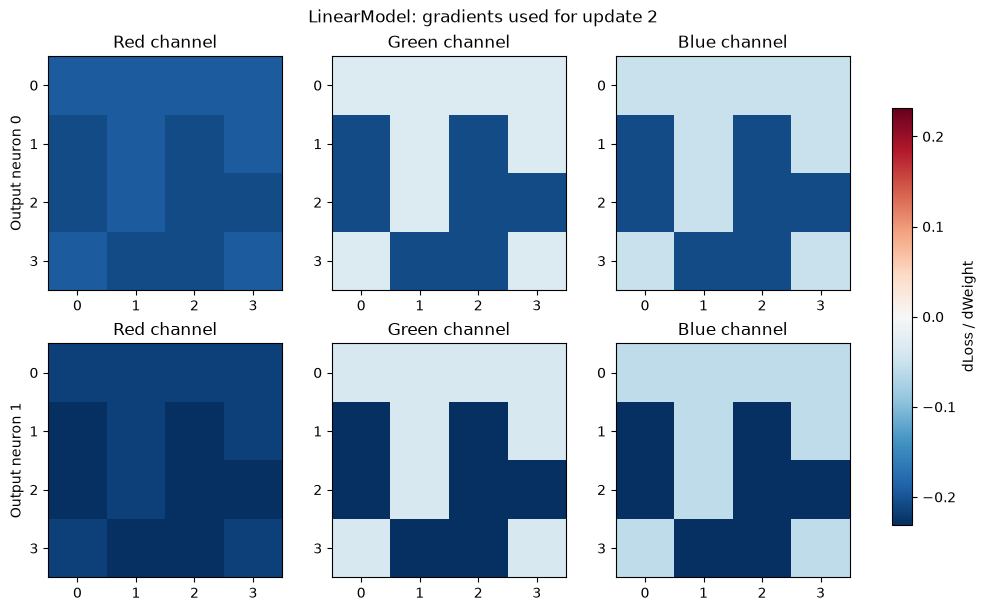

In [2]:
def plot_second_update_gradients(model_type, learning_rate, seed):
    torch.manual_seed(seed)
    model = model_type(image.shape, target.shape)

    first_output = model.calculate_output(image)
    first_gradients = model.calculate_gradients(image, first_output, target)
    first_loss = model.calculate_loss(first_output, target)
    model.update_weights(first_gradients, learning_rate)

    second_output = model.calculate_output(image)
    second_gradients = model.calculate_gradients(image, second_output, target)
    second_loss = model.calculate_loss(second_output, target)

    print(f"{model_type.__name__}, learning rate {learning_rate}")
    print(f"  step 1 output: {first_output.detach().tolist()}")
    print(f"  step 1 loss:   {first_loss.item():.6f}")
    print(f"  step 2 output: {second_output.detach().tolist()}")
    print(f"  step 2 loss:   {second_loss.item():.6f}")
    print(f"  target:        {target.tolist()}")

    gradient_array = second_gradients.detach().numpy()
    color_limit = abs(gradient_array).max().item()
    figure, axes = plt.subplots(2, 3, figsize=(10, 6), constrained_layout=True)
    image_handle = None
    for output_index in range(2):
        for channel in (RED, GREEN, BLUE):
            axis = axes[output_index, channel]
            image_handle = axis.imshow(
                gradient_array[:, :, channel, output_index],
                cmap="RdBu_r",
                vmin=-color_limit,
                vmax=color_limit,
                interpolation="none",
            )
            axis.set_title(f"{CHANNEL_NAMES[channel]} channel")
            axis.set_xticks(range(image.shape[1]))
            axis.set_yticks(range(image.shape[0]))
        axes[output_index, 0].set_ylabel(f"Output neuron {output_index}")
    figure.colorbar(image_handle, ax=axes, label="dLoss / dWeight", shrink=0.8)
    figure.suptitle(f"{model_type.__name__}: gradients used for update 2")
    plt.show()

    model.update_weights(second_gradients, learning_rate)
    return model


linear_model_after_two_updates = plot_second_update_gradients(
    LinearModel, learning_rate=0.01, seed=0
)

## Sigmoid model: gradients on the second update

neuron 0 is above target (positive gradient), neuron 1 is below target (negative gradient). Because of the derivative, the gradients are smaller.

LinearSigmoidModel, learning rate 0.2
  step 1 output: [0.48923686146736145, 0.6037696003913879]
  step 1 loss:   0.039309
  step 2 output: [0.401961088180542, 0.6521474719047546]
  step 2 loss:   0.016334
  target:        [0.25, 0.75]


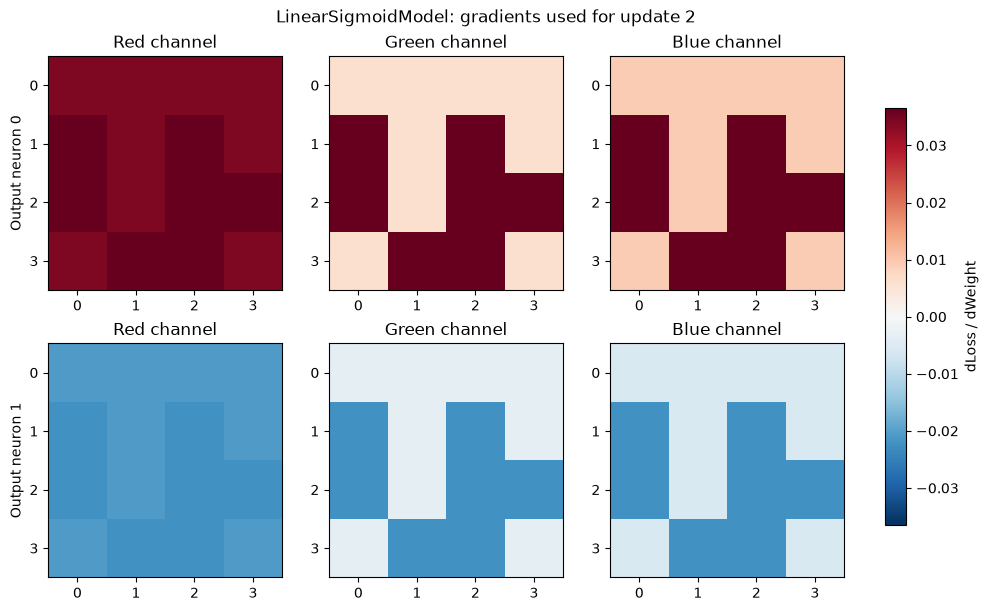

In [3]:
sigmoid_model_after_two_updates = plot_second_update_gradients(
    LinearSigmoidModel, learning_rate=0.2, seed=0
)

## Effect of learning rate on sigmoid training

Each curve starts from the same initial weights and trains for exactly 10 updates. The plotted loss is the loss measured immediately before each update.

[LinearSigmoidModel] fit step 1/10: loss = 0.03930880129337311
[LinearSigmoidModel] fit step 2/10: loss = 0.03929458186030388
[LinearSigmoidModel] fit step 3/10: loss = 0.03928038850426674
[LinearSigmoidModel] fit step 4/10: loss = 0.0392661951482296
[LinearSigmoidModel] fit step 5/10: loss = 0.039251990616321564
[LinearSigmoidModel] fit step 6/10: loss = 0.03923778980970383
[LinearSigmoidModel] fit step 7/10: loss = 0.039223603904247284
[LinearSigmoidModel] fit step 8/10: loss = 0.039209432899951935
[LinearSigmoidModel] fit step 9/10: loss = 0.039195265620946884
[LinearSigmoidModel] fit step 10/10: loss = 0.03918108716607094
[LinearSigmoidModel] fit step 1/10: loss = 0.03930880129337311
[LinearSigmoidModel] fit step 2/10: loss = 0.03916680067777634
[LinearSigmoidModel] fit step 3/10: loss = 0.03902532160282135
[LinearSigmoidModel] fit step 4/10: loss = 0.03888439014554024
[LinearSigmoidModel] fit step 5/10: loss = 0.03874398022890091
[LinearSigmoidModel] fit step 6/10: loss = 0.038604

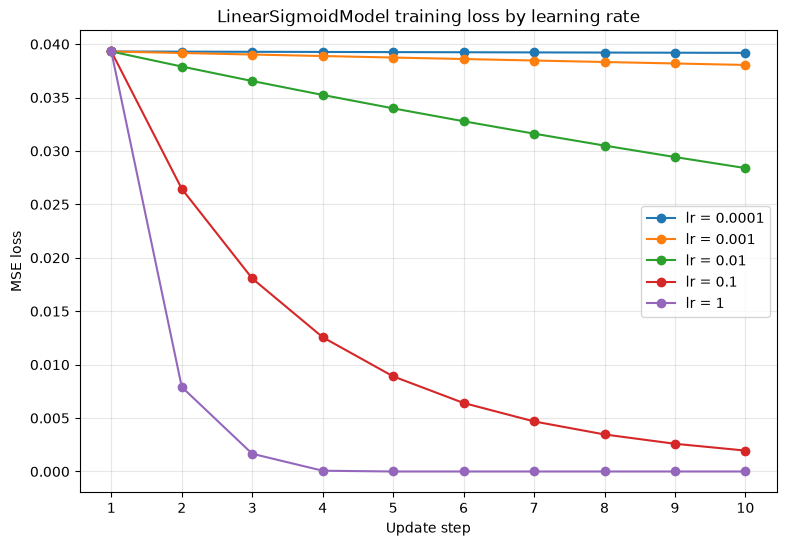

Final output after 10 updates (target: [0.25, 0.75] )
lr=0.0001: final loss=0.039181, output=[0.4887946546077728, 0.6040173172950745]
lr=0.001: final loss=0.038050, output=[0.48484939336776733, 0.606225311756134]
lr=0.01: final loss=0.028397, output=[0.4487735629081726, 0.6263197064399719]
lr=0.1: final loss=0.001957, output=[0.2943253219127655, 0.7181761860847473]
lr=1: final loss=0.000000, output=[0.25, 0.75]


In [4]:
learning_rates = [0.0001, 0.001, 0.01, 0.1, 1.0]
loss_histories = {}
final_outputs = {}

for learning_rate in learning_rates:
    torch.manual_seed(0)
    model = LinearSigmoidModel(image.shape, target.shape)
    losses = model.fit(image, target, steps=10, learning_rate=learning_rate)
    loss_histories[learning_rate] = losses
    final_outputs[learning_rate] = model.calculate_output(image).detach()

plt.figure(figsize=(9, 6))
steps = range(1, 11)
for learning_rate, losses in loss_histories.items():
    plt.plot(steps, losses, marker="o", label=f"lr = {learning_rate:g}")
plt.xlabel("Update step")
plt.ylabel("MSE loss")
plt.title("LinearSigmoidModel training loss by learning rate")
plt.xticks(list(steps))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print("Final output after 10 updates (target:", target.tolist(), ")")
for learning_rate in learning_rates:
    print(
        f"lr={learning_rate:g}: "
        f"final loss={loss_histories[learning_rate][-1]:.6f}, "
        f"output={final_outputs[learning_rate].tolist()}"
    )

### Comparing the curves

Smaller learing rate -> smaller weight changes, slow loss improvement.
Too high -> chance loss oscillates or rises again